In [1]:
#%load_ext autoreload
#%autoreload 2

In [2]:
import torch

torch.random.manual_seed(0)

In [3]:
import math
import os
import numpy as np
import pandas as pd
from tqdm.notebook import tqdm
import matplotlib.pyplot as plt

%matplotlib inline

In [4]:
#@title custom_callbacks.py
%%writefile custom_callbacks.py
import math
import numpy as np
import torch
import matplotlib.pyplot as plt
from pathlib import Path
import os

def save_weights(model, file):
  torch.save(model.state_dict(), file)

def reset_weights(model, file):
  model.load_state_dict(torch.load(file))

  return model


class CycleLearner(object):
  def __init__(self, model, optimizer, loss_function, lr, nb, n_cycle, cycle_len=1, cycle_mult=1,
                snapshots=False, n_snapshots=5,
                snapshots_name='temp_model', snapshots_folder='snapshots'):
    self.model = model
    self.optimizer = optimizer
    self.loss_function = loss_function
    self.lr = lr
    self.nb = nb*cycle_len
    self.n_cycle = n_cycle
    self.cycle_len = cycle_len
    self.cycle_mult = cycle_mult
    self.snapshots = snapshots
    self.n_snapshots = n_snapshots
    self.start_snaps = n_cycle - n_snapshots
    self.snapshots_name = snapshots_name
    self.snapshots_folder = snapshots_folder
    self.lr_list = []
    self.losses = []
    self.iterations = []
    self.stopped_training_because_n_cycle_reached = False

    if not os.path.exists(self.snapshots_folder):
      os.mkdir(self.snapshots_folder)

  def on_train_begin(self):
    self.iteration,self.epoch = 0,0
    self.cycle_iter,self.cycle_count=0,0
    self.update_lr()

  def on_cycle_end(self):
    self.cycle_iter = 0
    self.nb *= self.cycle_mult
    self.cycle_count += 1
    if self.snapshots and self.cycle_count>self.start_snaps:
      file_name = self.snapshots_folder +  '/'+ f'{self.snapshots_name}_{self.cycle_count}.pt'
      save_weights(self.model, file_name)

  def calc_lr(self):
    if self.iteration < self.nb/20:
      self.cycle_iter += 1
      return self.lr/100.

    cos_out = np.cos(np.pi*(self.cycle_iter)/self.nb) + 1
    self.cycle_iter += 1
    if self.cycle_iter==self.nb:
      self.on_cycle_end()

    return self.lr / 2 * cos_out

  def set_lr(self, new_lr):
    for group in self.optimizer.param_groups:
      group["lr"] = new_lr

  def update_lr(self):
    new_lr = self.calc_lr()
    self.set_lr(new_lr)

  def get_lr(self):
    lr = None

    for group in self.optimizer.param_groups:
      lr = group["lr"]

    return lr

  def on_train_batch_end(self, batch, predictions, y):
    with torch.no_grad():
      loss = self.loss_function(predictions, y).numpy().tolist()
      self.losses.append(loss)

    self.iteration += 1

    self.lr_list.append(self.get_lr())
    self.iterations.append(self.iteration)

    self.update_lr()

    if self.cycle_count == self.n_cycle:
      self.stopped_training_because_n_cycle_reached = True

  def should_stop_training(self):
    return self.stopped_training_because_n_cycle_reached

  def on_train_end(self):
    if self.stopped_training_because_n_cycle_reached:
      print("Stopped training because {} cycles were reached".format(self.n_cycle), flush=True)

  def plot_loss(self, skip=10):
    plt.xlabel("steps")
    plt.ylabel("loss")
    plt.plot(self.iterations[skip:], self.losses[skip:])

  def plot_lr(self):
    plt.xlabel("steps")
    plt.ylabel("learning rate")
    plt.plot(self.iterations, self.lr_list)


class LrFinder(object):
  def __init__(self, optimizer, loss_function, nb, start_lr=1e-5, end_lr=10):
    self.optimizer = optimizer
    self.loss_function = loss_function
    self.start_lr = start_lr
    self.lr = start_lr
    self.lr_mult = (end_lr/start_lr)**(1/nb)
    self.lr_list = []
    self.losses = []
    self.iterations = []
    self.derivatives = []
    self.stopped_training_because_nan = False
    self.stopped_training_because_suddenly_increases_too_much = False
    self.stop_at_batch = 0

  def on_train_begin(self):
    self.best = 1e9
    self.iteration = 0
    self.update_lr()

  def set_lr(self, new_lr):
    for group in self.optimizer.param_groups:
      group["lr"] = new_lr

  def update_lr(self):
    new_lr = self.start_lr * (self.lr_mult**self.iteration)
    self.set_lr(new_lr)

  def get_loss(self, predictions, y):
    return self.loss_function(predictions, batch_y)

  def get_lr(self):
    lr = None

    for group in self.optimizer.param_groups:
      lr = group["lr"]

    return lr

  def on_train_batch_end(self, batch, predictions, y):
    with torch.no_grad():
      loss = self.loss_function(predictions, y).numpy().tolist()
      self.losses.append(loss)

    self.iteration += 1

    self.lr_list.append(self.get_lr())
    self.iterations.append(self.iteration)

    if math.isnan(loss):
      self.stopped_training_because_nan  = True
      self.stop_at_batch = batch + 1

    if loss > self.best*4:
      self.stopped_training_because_suddenly_increases_too_much = True
      self.stop_at_batch = batch + 1

    if loss < self.best:
      self.best = loss

    self.update_lr()

  def should_stop_training(self):
    return self.stopped_training_because_nan or self.stopped_training_because_suddenly_increases_too_much

  def on_train_end(self):
    if self.stopped_training_because_nan:
      print("Stopped training at batch {} because the loss was nan".format(self.stop_at_batch), flush=True)

    if self.stopped_training_because_suddenly_increases_too_much:
      print("Stopped training at batch {} because the loss suddenly increases too much".format(self.stop_at_batch), flush=True)

  def plot_loss(self, skip=10):
    plt.xlabel("steps")
    plt.ylabel("loss")
    plt.plot(self.iterations[skip:], self.losses[skip:])

  def plot_lr(self):
    plt.xlabel("steps")
    plt.ylabel("learning rate")
    plt.plot(self.iterations, self.lr_list)

  def plot(self, use_log_scale=True, n_skip_start=2, xlim=None, ylim=None):
    plt.ylabel("loss")
    plt.xlabel("learning rate (log scale)")
    plt.plot(self.lr_list[n_skip_start:], self.losses[n_skip_start:])

    if use_log_scale:
      plt.xscale("log")
    if ylim is not None: plt.ylim(top=ylim)
    if xlim is not None: plt.xlim(right=xlim)

  def plot_loss_variation(self, window_size=1, xlim_range=None, ylim_range=None):
    '''
    Parameters:
      xlim_range - range used to obtain the learning rate values
      window_size - number of batches for simple moving average to smooth out the curve.
    '''
    assert (xlim_range!=None), "The parameter 'xlim_range' should be different from None"
    assert (window_size>0), "The parameter 'window_size' should be greater than 0"

    self.derivatives = []
    self.lr_list_on_xlim = []
    for i in range(len(self.lr_list)-window_size):
      if self.lr_list[i] < xlim_range[0]:
        continue
      if self.lr_list[i] > xlim_range[1]:
        break
      derivative = (self.losses[i + window_size] - self.losses[i]) / window_size
      self.derivatives.append(derivative)
      self.lr_list_on_xlim.append(self.lr_list[i])

    plt.ylabel("d/loss")
    plt.xlabel("learning rate (log scale)")
    plt.plot(self.lr_list_on_xlim, self.derivatives)
    plt.xscale('log')
    if ylim_range is not None: plt.ylim(ylim_range)
    if xlim_range is not None: plt.xlim(xlim_range)

Writing custom_callbacks.py


# MNIST

http://yann.lecun.com/exdb/mnist/

Base de datos de digitos escritos a mano.

* 60,000 imágenes de entrenamiento.
* 10,000 imágenes de test.

Cada imagen es de 28x28, en escala de grises.

In [5]:
from tensorflow.keras.datasets import mnist

(x_train, y_train), (x_test, y_test) = mnist.load_data()

11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


In [6]:
print(f'Train -> x: {x_train.shape}')
print(f'         y: {y_train.shape}')
print(f'Test ->  x: {x_test.shape}')
print(f'         y: {y_test.shape}')

Train -> x: (60000, 28, 28)
         y: (60000,)
Test ->  x: (10000, 28, 28)
         y: (10000,)


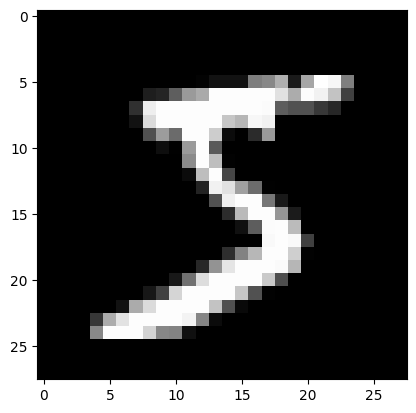

In [7]:
# Veamos una muestra
plt.imshow(x_train[0], 'gray');

In [8]:
y_train[0]

np.uint8(5)

In [9]:
# Veamos todas las clases del conjunto de entrenamiento
set(y_train)

{np.uint8(0),
 np.uint8(1),
 np.uint8(2),
 np.uint8(3),
 np.uint8(4),
 np.uint8(5),
 np.uint8(6),
 np.uint8(7),
 np.uint8(8),
 np.uint8(9)}

## Ajustamos las dimensiones de las imágenes

Para usar las imágenes en una multiplicación de matrices, esta necesita tener sólo 2 dimensiones.

In [10]:
x_train.shape

(60000, 28, 28)

In [11]:
x_train = x_train.reshape([-1, 28*28])
x_test = x_test.reshape([-1, 28*28])

x_train.shape, x_test.shape

((60000, 784), (10000, 784))

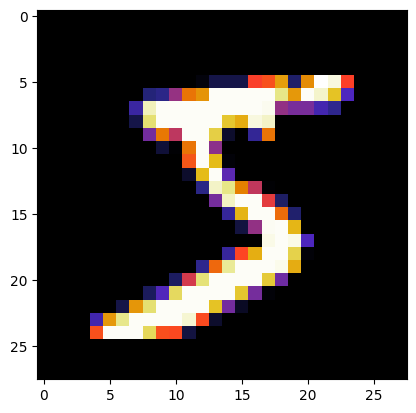

In [12]:
# Podemos usar el reshape de nuevo, para mostrar la imagen
plt.imshow(x_train[0].reshape([28,28]), 'CMRmap');

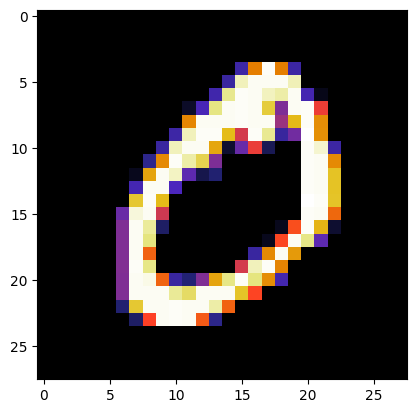

In [13]:
plt.imshow(x_train[1].reshape([28,28]), cmap='CMRmap');

## Definimos un modelo

In [14]:
%mkdir -p my_model

In [15]:
from custom_callbacks import save_weights

class NeuralNet(torch.nn.Module):
  def __init__(self):
    super(NeuralNet, self).__init__()

    self.dense_1 = torch.nn.Linear(784, 128)
    self.relu_1 = torch.nn.ReLU()
    self.dense_2 = torch.nn.Linear(128, 64)
    self.relu_2 = torch.nn.ReLU()
    self.output = torch.nn.Linear(64, 10)

  def forward(self, x):
    x = self.dense_1(x)
    x = self.relu_1(x)
    x = self.dense_2(x)
    x = self.relu_2(x)
    x = self.output(x)

    return x

def create_model():
  torch.cuda.empty_cache()

  model = NeuralNet()

  return model

In [16]:
lr = 0.01

model = create_model()

loss_function = torch.nn.CrossEntropyLoss()
optimizer = torch.optim.SGD(model.parameters(), lr=lr)

In [17]:
model.eval()

NeuralNet(
  (dense_1): Linear(in_features=784, out_features=128, bias=True)
  (relu_1): ReLU()
  (dense_2): Linear(in_features=128, out_features=64, bias=True)
  (relu_2): ReLU()
  (output): Linear(in_features=64, out_features=10, bias=True)
)

In [18]:
# Guardamos los pesos del modelo para poder usarlos posteriormente al re-inicializar los pesos
save_weights(model, 'my_model/model.pt')

In [19]:
bs = 256
nb = math.ceil(len(x_train)/bs) # Nro de batches

## Usemos el método de Learning rate finder

In [20]:
def train_for_lr_finder(model, loss_function, optimizer, lr_finder, nb, bs, x_train, y_train):
  lr_finder.on_train_begin()

  for i in range(nb):
    batch_x = torch.tensor(x_train[i*bs:(i+1)*bs], dtype=torch.float32)
    batch_y = torch.tensor(y_train[i*bs:(i+1)*bs], dtype=torch.int64)

    # PyTorch acumula gradientes, por eso necesitamos eliminarlas antes de cada instancia
    model.zero_grad()

    predictions = model(batch_x)

    loss = loss_function(predictions, batch_y)
    loss.backward()

    optimizer.step()

    lr_finder.on_train_batch_end(i, predictions, batch_y)

    if lr_finder.should_stop_training():
      break

  lr_finder.on_train_end()

  return lr_finder

In [21]:
from custom_callbacks import LrFinder

lr_finder = LrFinder(optimizer, loss_function, nb)

lr_finder = train_for_lr_finder(model, loss_function, optimizer, lr_finder, nb, bs, x_train, y_train)

Stopped training at batch 112 because the loss suddenly increases too much


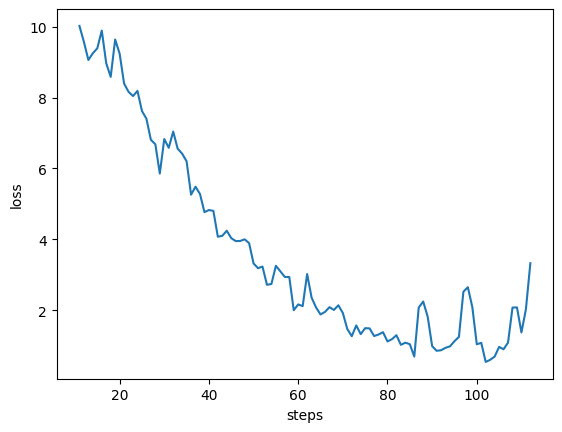

In [22]:
lr_finder.plot_loss()

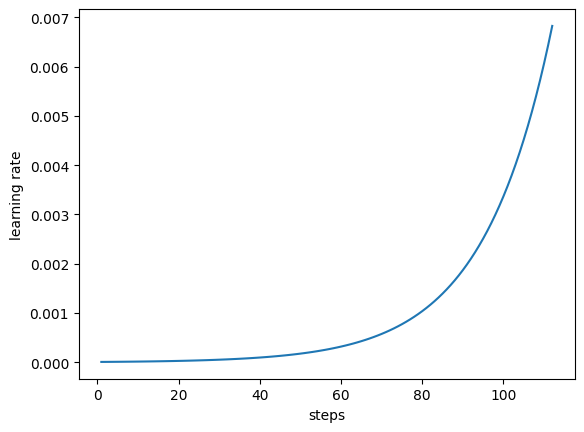

In [23]:
lr_finder.plot_lr()

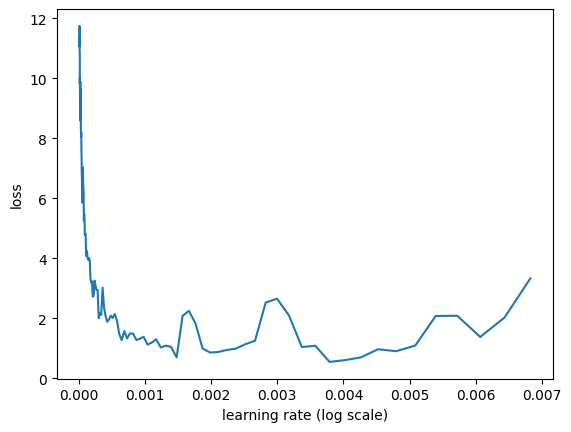

In [24]:
#Necesitamos seleccionar un punto donde el loss disminuya más rápido
lr_finder.plot(use_log_scale=False)

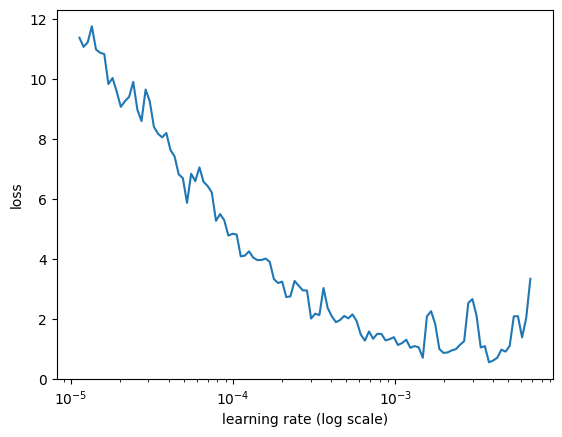

In [25]:
#Necesitamos seleccionar un punto donde el loss disminuya más rápido
lr_finder.plot(use_log_scale=True)

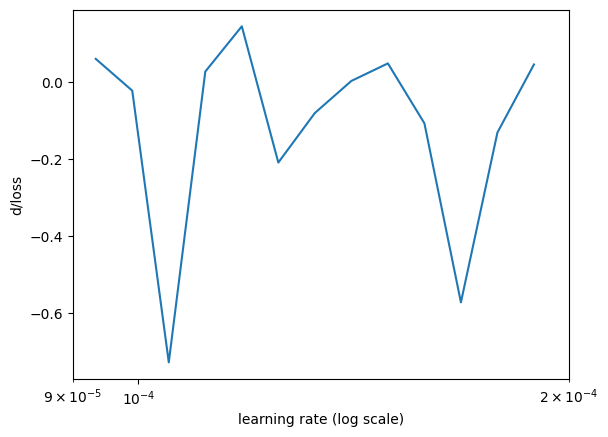

In [26]:
#d/loss es derivada del loss

#window_size - number of batches for simple moving average to smooth out the curve.
window_size = 1
#You can modify the range to adapt your plot
xlim_range=[9e-5, 2e-4]

lr_finder.plot_loss_variation(window_size=window_size, xlim_range=xlim_range)

In [27]:
index_of_the_min_derivative = np.argmin(lr_finder.derivatives)

lr = lr_finder.lr_list_on_xlim[index_of_the_min_derivative]

lr

0.00010502110796366623

### Entrenamiento

In [28]:
from custom_callbacks import reset_weights

# Reseteamos los pesos y compilamos el modelo con el nuevo lr porque la variable ya fue sobreescrita
model = reset_weights(model, 'my_model/model.pt')

loss_function = torch.nn.CrossEntropyLoss()
optimizer = torch.optim.SGD(model.parameters(), lr=lr)

In [29]:
def get_accuracy(predictions, y):
  comparison = predictions.max(dim=1).indices == y
  accuracy = torch.sum(comparison) / y.shape[0]
  accuracy = accuracy

  return accuracy

In [30]:
def train_model(model, loss_function, optimizer, nb, bs, epochs, x_train, y_train, x_test, y_test):
  train_losses = []
  test_losses = []

  train_accuracies = []
  test_accuracies = []

  for epoch in tqdm(range(epochs)):
    for i in range(nb):
      batch_x = torch.tensor(x_train[i*bs:(i+1)*bs], dtype=torch.float32)
      batch_y = torch.tensor(y_train[i*bs:(i+1)*bs], dtype=torch.int64)

      # PyTorch acumula gradientes, por eso necesitamos eliminarlas antes de cada instancia
      model.zero_grad()

      predictions = model(batch_x)

      loss = loss_function(predictions, batch_y)
      loss.backward()

      optimizer.step()

    with torch.no_grad():
      all_x_train = torch.tensor(x_train, dtype=torch.float32)
      all_y_train = torch.tensor(y_train, dtype=torch.int64)

      train_predictions = model(all_x_train)

      train_loss = loss_function(train_predictions, all_y_train)
      train_losses.append(train_loss)

      train_predictions = torch.nn.functional.softmax(train_predictions, dim=-1)
      train_accuracy = get_accuracy(train_predictions, all_y_train)
      train_accuracies.append(train_accuracy)

      all_x_test = torch.tensor(x_test, dtype=torch.float32)
      all_y_test = torch.tensor(y_test, dtype=torch.int64)

      test_predictions = model(all_x_test)

      test_loss = loss_function(test_predictions, all_y_test)
      test_losses.append(test_loss)

      test_predictions = torch.nn.functional.softmax(test_predictions, dim=-1)
      test_accuracy = get_accuracy(test_predictions, all_y_test)
      test_accuracies.append(test_accuracy)

      print("Epoch {}/{}\n----> loss: {:.4f} - accuracy: {:.4f} - val_loss: {:.4f} - val_accuracy: {:.4f}".format(epoch+1, epochs, train_loss.numpy(), train_accuracy.numpy(), test_loss.numpy(), test_accuracy.numpy()))

  return train_losses, test_losses, train_accuracies, test_accuracies

In [31]:
epochs = 6

train_losses, test_losses, train_accuracies, test_accuracies = train_model(model, loss_function, optimizer, nb, bs, epochs, x_train, y_train, x_test, y_test)

  0%|          | 0/6 [00:00<?, ?it/s]

Epoch 1/6
----> loss: 1.0211 - accuracy: 0.7085 - val_loss: 0.9624 - val_accuracy: 0.7209
Epoch 2/6
----> loss: 0.7319 - accuracy: 0.7870 - val_loss: 0.6932 - val_accuracy: 0.7966
Epoch 3/6
----> loss: 0.6077 - accuracy: 0.8224 - val_loss: 0.5804 - val_accuracy: 0.8294
Epoch 4/6
----> loss: 0.5340 - accuracy: 0.8443 - val_loss: 0.5146 - val_accuracy: 0.8492
Epoch 5/6
----> loss: 0.4836 - accuracy: 0.8588 - val_loss: 0.4701 - val_accuracy: 0.8627
Epoch 6/6
----> loss: 0.4465 - accuracy: 0.8689 - val_loss: 0.4374 - val_accuracy: 0.8715


In [32]:
def make_evaluation(model, x, y):
  with torch.no_grad():
    x = torch.tensor(x, dtype=torch.float32)
    y = torch.tensor(y, dtype=torch.int64)

    predictions = model(x)

    loss = loss_function(predictions, y).numpy().tolist()

    predictions = torch.nn.functional.softmax(predictions, dim=-1)
    accuracy = get_accuracy(predictions, y).numpy().tolist()

    return loss, accuracy

In [33]:
def show_results(model, train_losses, test_losses, train_accuracies, test_accuracies):
    loss, acc = make_evaluation(model, x_test, y_test)
    print(f'Loss     = {loss:.4f}')
    print(f'Accuracy = {acc:.4f}')

    fig, axes = plt.subplots(1, 2, figsize=(14,4))
    ax1, ax2 = axes
    ax1.plot(train_losses, label='train')
    ax1.plot(test_losses, label='test')
    ax1.set_xlabel('epoch'); ax1.set_ylabel('loss')
    ax2.plot(train_accuracies, label='train')
    ax2.plot(test_accuracies, label='test')
    ax2.set_xlabel('epoch'); ax2.set_ylabel('accuracy')
    for ax in axes: ax.legend()

Loss     = 0.4374
Accuracy = 0.8715


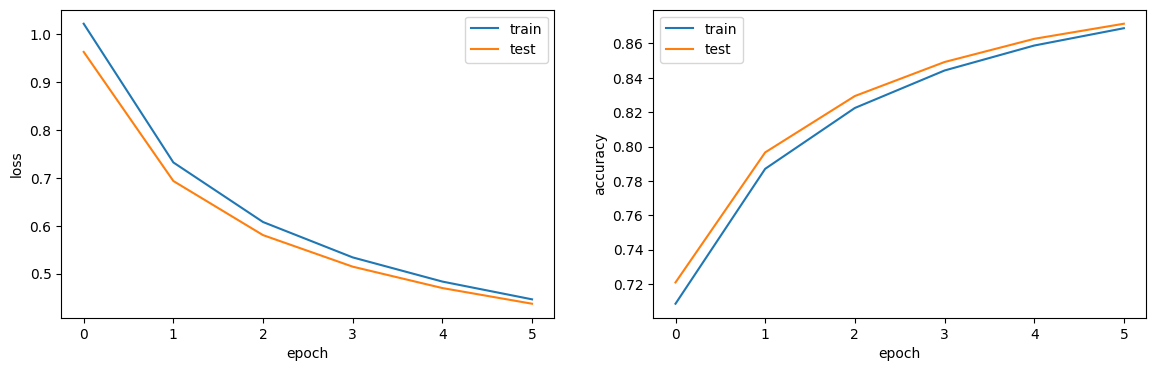

In [34]:
show_results(model, train_losses, test_losses, train_accuracies, test_accuracies)

## Cycling learning rates

In [35]:
from custom_callbacks import CycleLearner

cycle_learner = CycleLearner(model, optimizer, loss_function, lr, nb, n_cycle=3)

### Entrenamiento

In [36]:
def train_for_cycle_learner(model, loss_function, optimizer, cycle_learner, nb, bs, epochs, x_train, y_train, x_test, y_test):
  train_losses = []
  test_losses = []

  train_accuracies = []
  test_accuracies = []

  bar = tqdm(range(epochs))

  cycle_learner.on_train_begin()

  for epoch in bar:
    for i in range(nb):
      batch_x = torch.tensor(x_train[i*bs:(i+1)*bs], dtype=torch.float32)
      batch_y = torch.tensor(y_train[i*bs:(i+1)*bs], dtype=torch.int64)

      # PyTorch acumula gradientes, por eso necesitamos eliminarlas antes de cada instancia
      model.zero_grad()

      predictions = model(batch_x)

      loss = loss_function(predictions, batch_y)
      loss.backward()

      optimizer.step()

      cycle_learner.on_train_batch_end(i, predictions, batch_y)

      if cycle_learner.should_stop_training():
        break

    with torch.no_grad():
      all_x_train = torch.tensor(x_train, dtype=torch.float32)
      all_y_train = torch.tensor(y_train, dtype=torch.int64)

      train_predictions = model(all_x_train)

      train_loss = loss_function(train_predictions, all_y_train)
      train_losses.append(train_loss)

      train_predictions = torch.nn.functional.softmax(train_predictions, dim=-1)
      train_accuracy = get_accuracy(train_predictions, all_y_train)
      train_accuracies.append(train_accuracy)

      all_x_test = torch.tensor(x_test, dtype=torch.float32)
      all_y_test = torch.tensor(y_test, dtype=torch.int64)

      test_predictions = model(all_x_test)

      test_loss = loss_function(test_predictions, all_y_test)
      test_losses.append(test_loss)

      test_predictions = torch.nn.functional.softmax(test_predictions, dim=-1)
      test_accuracy = get_accuracy(test_predictions, all_y_test)
      test_accuracies.append(test_accuracy)

      print("Epoch {}/{}\n----> loss: {:.4f} - accuracy: {:.4f} - val_loss: {:.4f} - val_accuracy: {:.4f}".format(epoch+1, epochs, train_loss.numpy(), train_accuracy.numpy(), test_loss.numpy(), test_accuracy.numpy()))

    bar.update(1)

    if cycle_learner.should_stop_training():
        break

  cycle_learner.on_train_end()

  return train_losses, test_losses, train_accuracies, test_accuracies

In [37]:
from custom_callbacks import reset_weights

model = reset_weights(model, 'my_model/model.pt')

loss_function = torch.nn.CrossEntropyLoss()
optimizer = torch.optim.SGD(model.parameters(), lr=lr)

epochs = 100

train_losses, test_losses, train_accuracies, test_accuracies = train_for_cycle_learner(model, loss_function, optimizer, cycle_learner, nb, bs, epochs, x_train, y_train, x_test, y_test)

  0%|          | 0/100 [00:00<?, ?it/s]

Epoch 1/100
----> loss: 1.0211 - accuracy: 0.7085 - val_loss: 0.9624 - val_accuracy: 0.7209
Epoch 2/100
----> loss: 0.7319 - accuracy: 0.7870 - val_loss: 0.6932 - val_accuracy: 0.7966
Epoch 3/100
----> loss: 0.6079 - accuracy: 0.8227 - val_loss: 0.5800 - val_accuracy: 0.8301
Stopped training because 3 cycles were reached


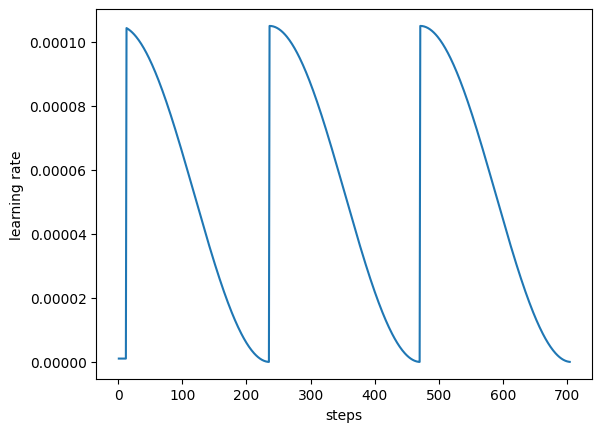

In [38]:
cycle_learner.plot_lr()

Loss     = 0.5800
Accuracy = 0.8301


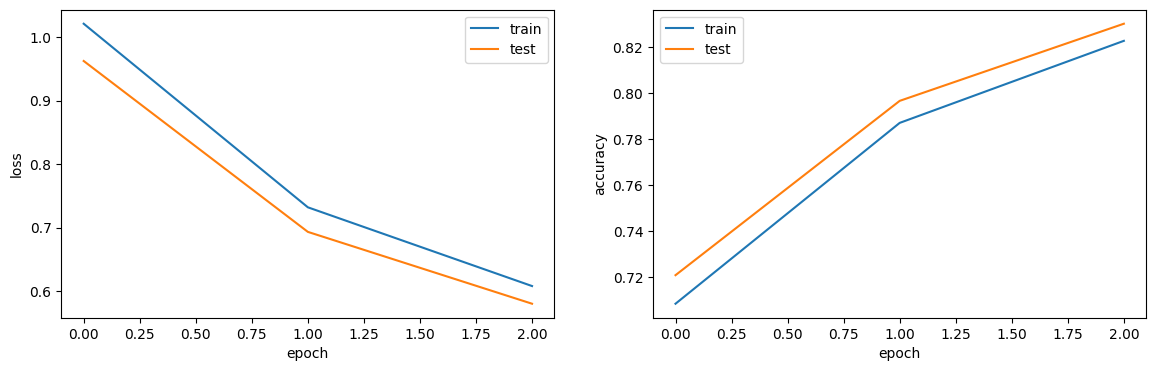

In [39]:
show_results(model, train_losses, test_losses, train_accuracies, test_accuracies)

In [40]:
from custom_callbacks import reset_weights

# El parametro "cycle_mult" permite que cada ciclo sea mayor al anterior,
# en este caso el doble del anterior

model = reset_weights(model, 'my_model/model.pt')

loss_function = torch.nn.CrossEntropyLoss()
optimizer = torch.optim.SGD(model.parameters(), lr=lr)

cycle_learner = CycleLearner(model, optimizer, loss_function, lr/2, nb, n_cycle=3, cycle_mult=2)

epochs = 100

train_losses, test_losses, train_accuracies, test_accuracies = train_for_cycle_learner(model, loss_function, optimizer, cycle_learner, nb, bs, epochs, x_train, y_train, x_test, y_test)

  0%|          | 0/100 [00:00<?, ?it/s]

Epoch 1/100
----> loss: 2.2389 - accuracy: 0.4498 - val_loss: 2.1424 - val_accuracy: 0.4639
Epoch 2/100
----> loss: 1.2877 - accuracy: 0.6421 - val_loss: 1.2138 - val_accuracy: 0.6534
Epoch 3/100
----> loss: 1.2017 - accuracy: 0.6618 - val_loss: 1.1326 - val_accuracy: 0.6738
Epoch 4/100
----> loss: 0.9327 - accuracy: 0.7308 - val_loss: 0.8792 - val_accuracy: 0.7420
Epoch 5/100
----> loss: 0.8257 - accuracy: 0.7611 - val_loss: 0.7793 - val_accuracy: 0.7708
Epoch 6/100
----> loss: 0.7885 - accuracy: 0.7712 - val_loss: 0.7447 - val_accuracy: 0.7814
Epoch 7/100
----> loss: 0.7831 - accuracy: 0.7724 - val_loss: 0.7396 - val_accuracy: 0.7829
Stopped training because 3 cycles were reached


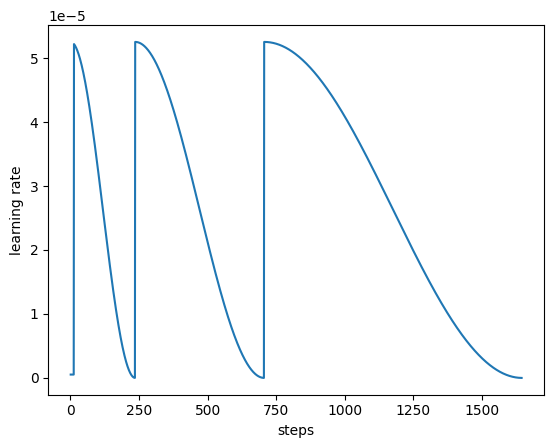

In [41]:
cycle_learner.plot_lr()

Loss     = 0.7396
Accuracy = 0.7829


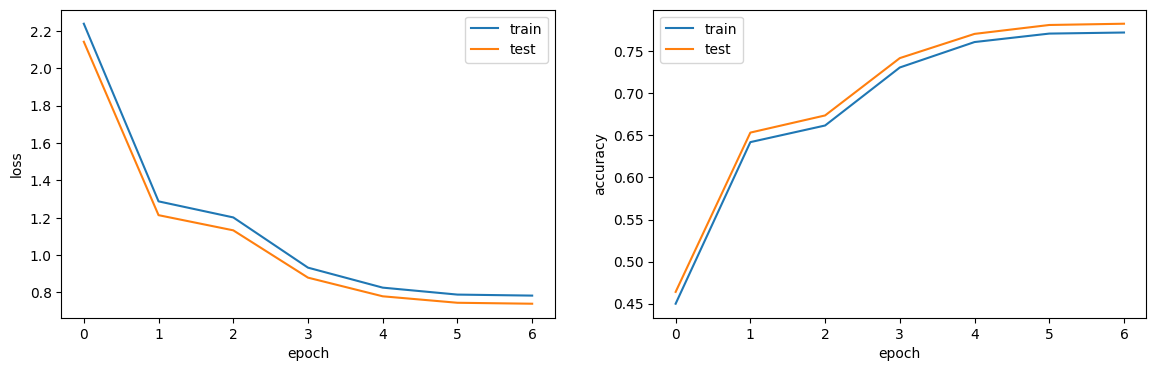

In [42]:
show_results(model, train_losses, test_losses, train_accuracies, test_accuracies)

In [43]:
from custom_callbacks import reset_weights

# El parametro "cycle_len" permite que cada ciclo sea N veces mayor,
# en este caso 2 veces más grande

model = reset_weights(model, 'my_model/model.pt')

loss_function = torch.nn.CrossEntropyLoss()
optimizer = torch.optim.SGD(model.parameters(), lr=lr)

cycle_learner = CycleLearner(model, optimizer, loss_function, lr/2, nb, n_cycle=3, cycle_len=2)

epochs = 100

train_losses, test_losses, train_accuracies, test_accuracies = train_for_cycle_learner(model, loss_function, optimizer, cycle_learner, nb, bs, epochs, x_train, y_train, x_test, y_test)

  0%|          | 0/100 [00:00<?, ?it/s]

Epoch 1/100
----> loss: 1.7455 - accuracy: 0.5414 - val_loss: 1.6524 - val_accuracy: 0.5566
Epoch 2/100
----> loss: 1.5468 - accuracy: 0.5821 - val_loss: 1.4608 - val_accuracy: 0.5958
Epoch 3/100
----> loss: 1.1028 - accuracy: 0.6869 - val_loss: 1.0382 - val_accuracy: 0.6998
Epoch 4/100
----> loss: 1.0481 - accuracy: 0.7012 - val_loss: 0.9869 - val_accuracy: 0.7125
Epoch 5/100
----> loss: 0.8784 - accuracy: 0.7454 - val_loss: 0.8282 - val_accuracy: 0.7556
Epoch 6/100
----> loss: 0.8512 - accuracy: 0.7540 - val_loss: 0.8027 - val_accuracy: 0.7623
Stopped training because 3 cycles were reached


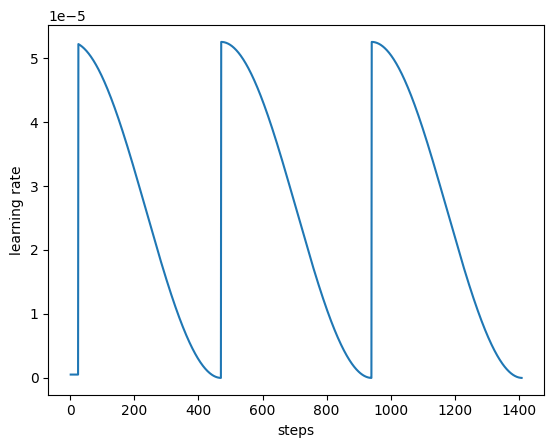

In [44]:
cycle_learner.plot_lr()

Loss     = 0.8027
Accuracy = 0.7623


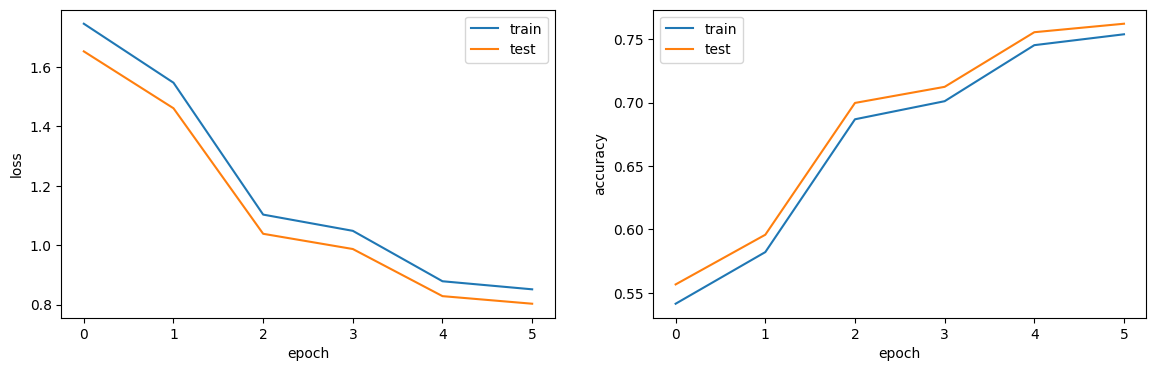

In [45]:
show_results(model, train_losses, test_losses, train_accuracies, test_accuracies)

## Snapshot ensembles

In [46]:
from custom_callbacks import reset_weights

# Iniciamos el entrenamiento de forma normal

model = reset_weights(model, 'my_model/model.pt')

loss_function = torch.nn.CrossEntropyLoss()
optimizer = torch.optim.SGD(model.parameters(), lr=lr)

cycle_learner = CycleLearner(model, optimizer, loss_function, lr, nb, n_cycle=5, cycle_mult=2)

epochs = 100

train_losses, test_losses, train_accuracies, test_accuracies = train_for_cycle_learner(model, loss_function, optimizer, cycle_learner, nb, bs, epochs, x_train, y_train, x_test, y_test)

  0%|          | 0/100 [00:00<?, ?it/s]

Epoch 1/100
----> loss: 1.5353 - accuracy: 0.5837 - val_loss: 1.4528 - val_accuracy: 0.5975
Epoch 2/100
----> loss: 0.9051 - accuracy: 0.7386 - val_loss: 0.8538 - val_accuracy: 0.7479
Epoch 3/100
----> loss: 0.8485 - accuracy: 0.7543 - val_loss: 0.8011 - val_accuracy: 0.7639
Epoch 4/100
----> loss: 0.6714 - accuracy: 0.8041 - val_loss: 0.6383 - val_accuracy: 0.8116
Epoch 5/100
----> loss: 0.5985 - accuracy: 0.8255 - val_loss: 0.5722 - val_accuracy: 0.8328
Epoch 6/100
----> loss: 0.5728 - accuracy: 0.8330 - val_loss: 0.5490 - val_accuracy: 0.8407
Epoch 7/100
----> loss: 0.5690 - accuracy: 0.8342 - val_loss: 0.5453 - val_accuracy: 0.8413
Epoch 8/100
----> loss: 0.5092 - accuracy: 0.8505 - val_loss: 0.4932 - val_accuracy: 0.8561
Epoch 9/100
----> loss: 0.4689 - accuracy: 0.8627 - val_loss: 0.4576 - val_accuracy: 0.8654
Epoch 10/100
----> loss: 0.4418 - accuracy: 0.8702 - val_loss: 0.4336 - val_accuracy: 0.8726
Epoch 11/100
----> loss: 0.4242 - accuracy: 0.8755 - val_loss: 0.4180 - val_acc

Loss     = 0.3067
Accuracy = 0.9112


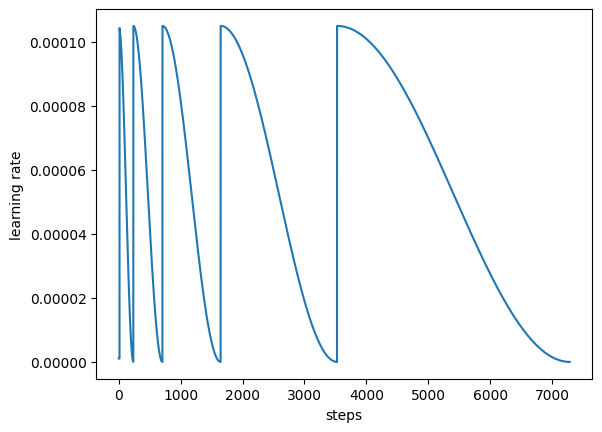

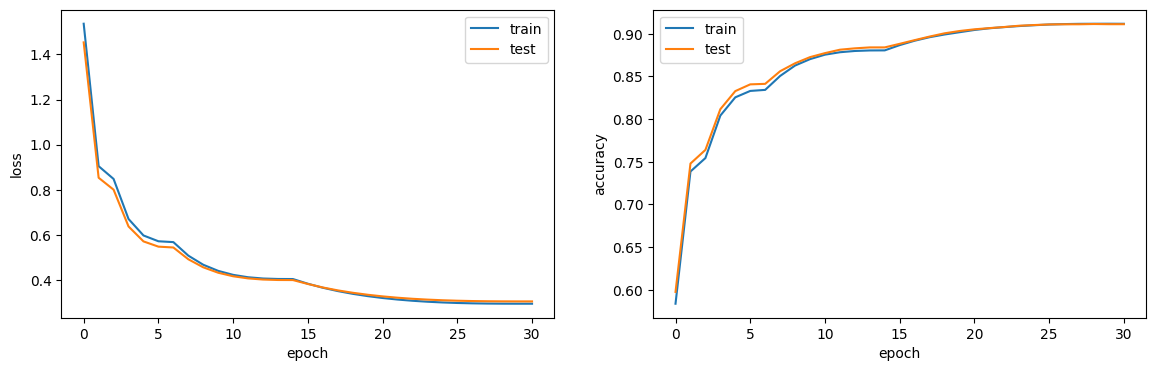

In [47]:
cycle_learner.plot_lr()
show_results(model, train_losses, test_losses, train_accuracies, test_accuracies)

In [48]:
cycle_learner = CycleLearner(model, optimizer, loss_function, lr/2, nb, n_cycle=3, snapshots=True, snapshots_name='mnist_test')

epochs = 100

train_losses, test_losses, train_accuracies, test_accuracies = train_for_cycle_learner(model, loss_function, optimizer, cycle_learner, nb, bs, epochs, x_train, y_train, x_test, y_test)

  0%|          | 0/100 [00:00<?, ?it/s]

Epoch 1/100
----> loss: 0.2947 - accuracy: 0.9120 - val_loss: 0.3051 - val_accuracy: 0.9118
Epoch 2/100
----> loss: 0.2927 - accuracy: 0.9127 - val_loss: 0.3034 - val_accuracy: 0.9126
Epoch 3/100
----> loss: 0.2908 - accuracy: 0.9134 - val_loss: 0.3017 - val_accuracy: 0.9131
Stopped training because 3 cycles were reached


Loss     = 0.3017
Accuracy = 0.9131


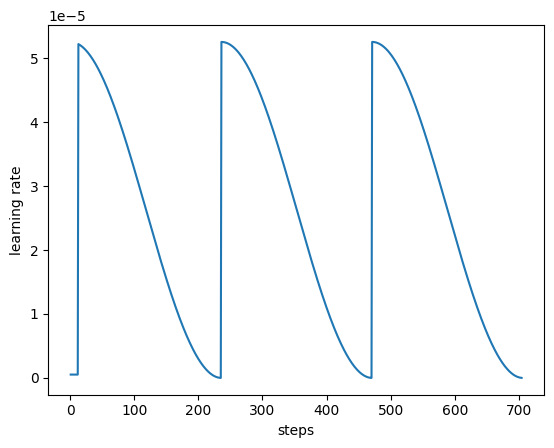

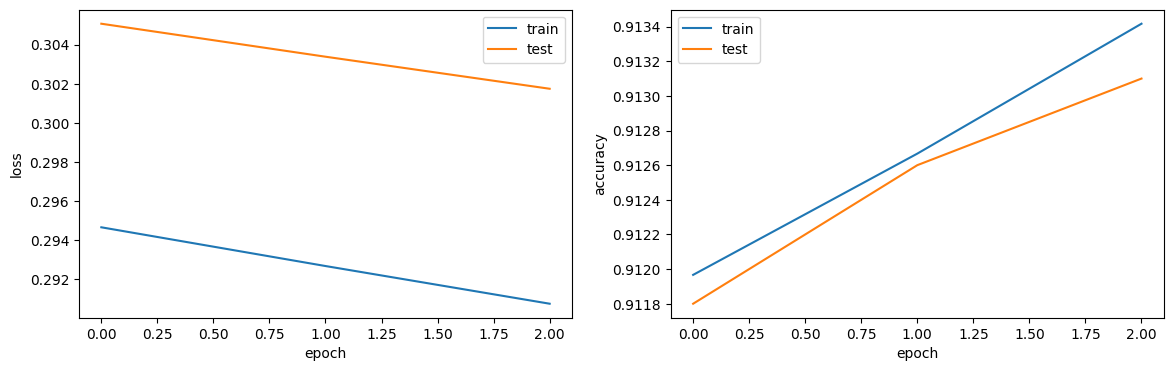

In [49]:
cycle_learner.plot_lr()
show_results(model, train_losses, test_losses, train_accuracies, test_accuracies)

In [50]:
# Veamos los archivos creados para los snapshots
snapshots = 'snapshots'
snapshots_file_names = list()

for snapshot_file in os.listdir(snapshots):
  snapshot_file_name = os.path.join(snapshots, snapshot_file)

  snapshots_file_names.append(snapshot_file_name)

  print(snapshot_file_name)

snapshots/mnist_test_3.pt
snapshots/mnist_test_1.pt
snapshots/mnist_test_2.pt


In [51]:
# Veamos ahora usando snapshots
snapshots_results = np.zeros([10000,10])

for snapshot_file_name in snapshots_file_names:
  model = reset_weights(model, snapshot_file_name)

  with torch.no_grad():
    x_test_as_tensor = torch.tensor(x_test, dtype=torch.float32)
    prediction = model(x_test_as_tensor).numpy()

    snapshots_results += prediction / len(snapshots_file_names)

acc = (snapshots_results.argmax(axis=1) == y_test).mean()
print(f'Snapshot accuracy = {acc}')

Snapshot accuracy = 0.9126


## Test Optimizers

In [52]:
from torch.optim import SGD, Adam, RMSprop, Adagrad

#Definición de los parámetros para compilar los modelos
learning_rate = lr
optimizers_names = ['sgd', 'adam', 'rmsprop', 'adagrad']

#Creación de los modelos
models = [create_model() for _ in range(len(optimizers_names))]

#Reseteamos los pesos
models = [reset_weights(model, 'my_model/model.pt') for model in models]

#Creación de los loss
losses_functions = [torch.nn.CrossEntropyLoss() for model in models]

#Creación de los optimizers
optimizers = [SGD, Adam, RMSprop, Adagrad]
optimizers = [optimizer(model.parameters(), lr=learning_rate) for optimizer, model in zip(optimizers, models)]

In [53]:
#Entrenamiento de los modelos
histories = list()

epochs = 10

for optimizer_name, optimizer, loss_function, model in zip(optimizers_names, optimizers, losses_functions, models):
  print("Training for optimizer {}".format(optimizer_name), flush=True)
  train_losses, test_losses, train_accuracies, test_accuracies = train_model(model, loss_function, optimizer, nb, bs, epochs, x_train, y_train, x_test, y_test)
  histories.append([train_losses, test_losses, train_accuracies, test_accuracies])
  print(flush=True)

Training for optimizer sgd


  0%|          | 0/10 [00:00<?, ?it/s]

Epoch 1/10
----> loss: 1.0211 - accuracy: 0.7085 - val_loss: 0.9624 - val_accuracy: 0.7209
Epoch 2/10
----> loss: 0.7319 - accuracy: 0.7870 - val_loss: 0.6932 - val_accuracy: 0.7966
Epoch 3/10
----> loss: 0.6077 - accuracy: 0.8224 - val_loss: 0.5804 - val_accuracy: 0.8294
Epoch 4/10
----> loss: 0.5340 - accuracy: 0.8443 - val_loss: 0.5146 - val_accuracy: 0.8492
Epoch 5/10
----> loss: 0.4836 - accuracy: 0.8588 - val_loss: 0.4701 - val_accuracy: 0.8627
Epoch 6/10
----> loss: 0.4465 - accuracy: 0.8689 - val_loss: 0.4374 - val_accuracy: 0.8715
Epoch 7/10
----> loss: 0.4177 - accuracy: 0.8767 - val_loss: 0.4121 - val_accuracy: 0.8797
Epoch 8/10
----> loss: 0.3944 - accuracy: 0.8837 - val_loss: 0.3918 - val_accuracy: 0.8858
Epoch 9/10
----> loss: 0.3749 - accuracy: 0.8896 - val_loss: 0.3749 - val_accuracy: 0.8908
Epoch 10/10
----> loss: 0.3583 - accuracy: 0.8945 - val_loss: 0.3604 - val_accuracy: 0.8942

Training for optimizer adam


  0%|          | 0/10 [00:00<?, ?it/s]

Epoch 1/10
----> loss: 0.3695 - accuracy: 0.8916 - val_loss: 0.3766 - val_accuracy: 0.8924
Epoch 2/10
----> loss: 0.2352 - accuracy: 0.9304 - val_loss: 0.2617 - val_accuracy: 0.9265
Epoch 3/10
----> loss: 0.1771 - accuracy: 0.9474 - val_loss: 0.2174 - val_accuracy: 0.9383
Epoch 4/10
----> loss: 0.1395 - accuracy: 0.9584 - val_loss: 0.1909 - val_accuracy: 0.9456
Epoch 5/10
----> loss: 0.1142 - accuracy: 0.9657 - val_loss: 0.1741 - val_accuracy: 0.9491
Epoch 6/10
----> loss: 0.0956 - accuracy: 0.9717 - val_loss: 0.1616 - val_accuracy: 0.9525
Epoch 7/10
----> loss: 0.0808 - accuracy: 0.9762 - val_loss: 0.1512 - val_accuracy: 0.9548
Epoch 8/10
----> loss: 0.0692 - accuracy: 0.9798 - val_loss: 0.1446 - val_accuracy: 0.9569
Epoch 9/10
----> loss: 0.0595 - accuracy: 0.9828 - val_loss: 0.1394 - val_accuracy: 0.9576
Epoch 10/10
----> loss: 0.0515 - accuracy: 0.9855 - val_loss: 0.1353 - val_accuracy: 0.9601

Training for optimizer rmsprop


  0%|          | 0/10 [00:00<?, ?it/s]

Epoch 1/10
----> loss: 0.2805 - accuracy: 0.9154 - val_loss: 0.3030 - val_accuracy: 0.9125
Epoch 2/10
----> loss: 0.1868 - accuracy: 0.9422 - val_loss: 0.2245 - val_accuracy: 0.9351
Epoch 3/10
----> loss: 0.1339 - accuracy: 0.9588 - val_loss: 0.1825 - val_accuracy: 0.9484
Epoch 4/10
----> loss: 0.1023 - accuracy: 0.9687 - val_loss: 0.1616 - val_accuracy: 0.9537
Epoch 5/10
----> loss: 0.0817 - accuracy: 0.9749 - val_loss: 0.1490 - val_accuracy: 0.9570
Epoch 6/10
----> loss: 0.0648 - accuracy: 0.9800 - val_loss: 0.1393 - val_accuracy: 0.9603
Epoch 7/10
----> loss: 0.0532 - accuracy: 0.9837 - val_loss: 0.1340 - val_accuracy: 0.9612
Epoch 8/10
----> loss: 0.0446 - accuracy: 0.9864 - val_loss: 0.1304 - val_accuracy: 0.9630
Epoch 9/10
----> loss: 0.0377 - accuracy: 0.9892 - val_loss: 0.1276 - val_accuracy: 0.9650
Epoch 10/10
----> loss: 0.0313 - accuracy: 0.9907 - val_loss: 0.1277 - val_accuracy: 0.9649

Training for optimizer adagrad


  0%|          | 0/10 [00:00<?, ?it/s]

Epoch 1/10
----> loss: 1.4994 - accuracy: 0.5996 - val_loss: 1.4245 - val_accuracy: 0.6137
Epoch 2/10
----> loss: 1.1108 - accuracy: 0.6891 - val_loss: 1.0543 - val_accuracy: 0.7017
Epoch 3/10
----> loss: 0.9395 - accuracy: 0.7335 - val_loss: 0.8932 - val_accuracy: 0.7435
Epoch 4/10
----> loss: 0.8366 - accuracy: 0.7603 - val_loss: 0.7978 - val_accuracy: 0.7689
Epoch 5/10
----> loss: 0.7655 - accuracy: 0.7800 - val_loss: 0.7325 - val_accuracy: 0.7877
Epoch 6/10
----> loss: 0.7128 - accuracy: 0.7940 - val_loss: 0.6845 - val_accuracy: 0.8023
Epoch 7/10
----> loss: 0.6714 - accuracy: 0.8053 - val_loss: 0.6468 - val_accuracy: 0.8126
Epoch 8/10
----> loss: 0.6375 - accuracy: 0.8152 - val_loss: 0.6162 - val_accuracy: 0.8210
Epoch 9/10
----> loss: 0.6092 - accuracy: 0.8233 - val_loss: 0.5907 - val_accuracy: 0.8286
Epoch 10/10
----> loss: 0.5850 - accuracy: 0.8301 - val_loss: 0.5689 - val_accuracy: 0.8355



In [54]:
def plot_history_with_optimizers(axis, histories, metric, title, y_label, x_label, legend):
  plt.figure(figsize=(10, 6))
  plt.axis(axis)

  for train_losses, test_losses, train_accuracies, test_accuracies in histories:
    if metric == "loss":
      plt.plot(train_losses)
    elif metric == "accuracy":
      plt.plot(train_accuracies)
    if metric == "val_loss":
      plt.plot(test_losses)
    elif metric == "val_accuracy":
      plt.plot(test_accuracies)

  plt.title(title)
  plt.ylabel(y_label)
  plt.xlabel(x_label)
  plt.legend(legend, loc='lower right')
  plt.show()

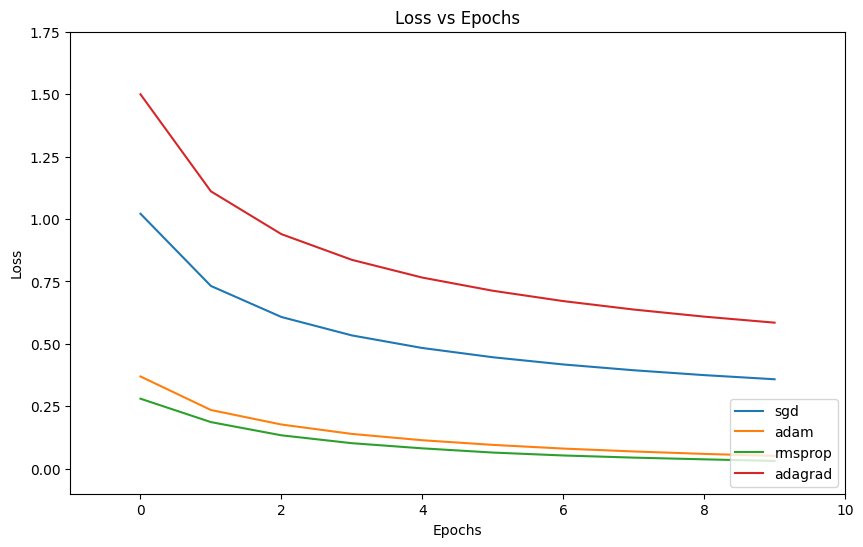

In [55]:
axis = (-1, 10, -0.1, 1.75)
metric = 'loss'
title = 'Loss vs Epochs'
y_label = 'Loss'
x_label = 'Epochs'

plot_history_with_optimizers(axis, histories, metric, title, y_label, x_label, optimizers_names)

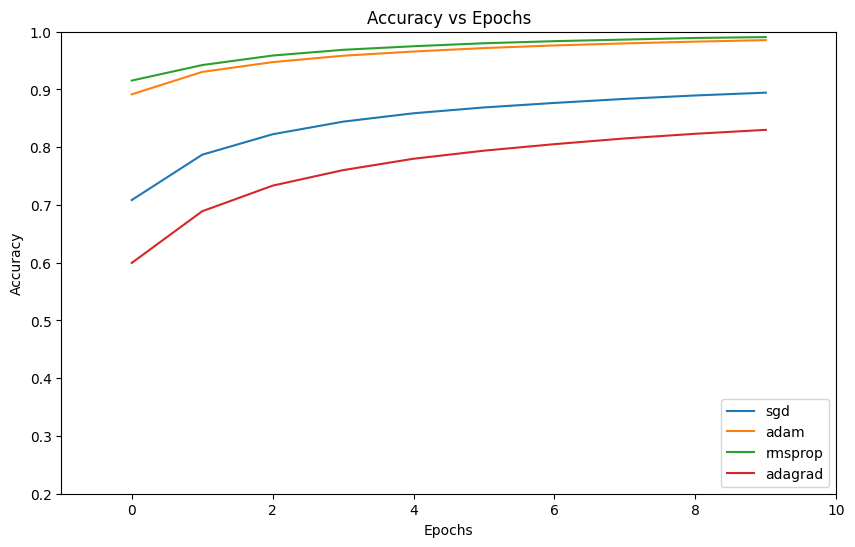

In [56]:
axis = (-1, 10, 0.2, 1)
metric = 'accuracy'
title = 'Accuracy vs Epochs'
y_label = 'Accuracy'
x_label = 'Epochs'

plot_history_with_optimizers(axis, histories, metric, title, y_label, x_label, optimizers_names)

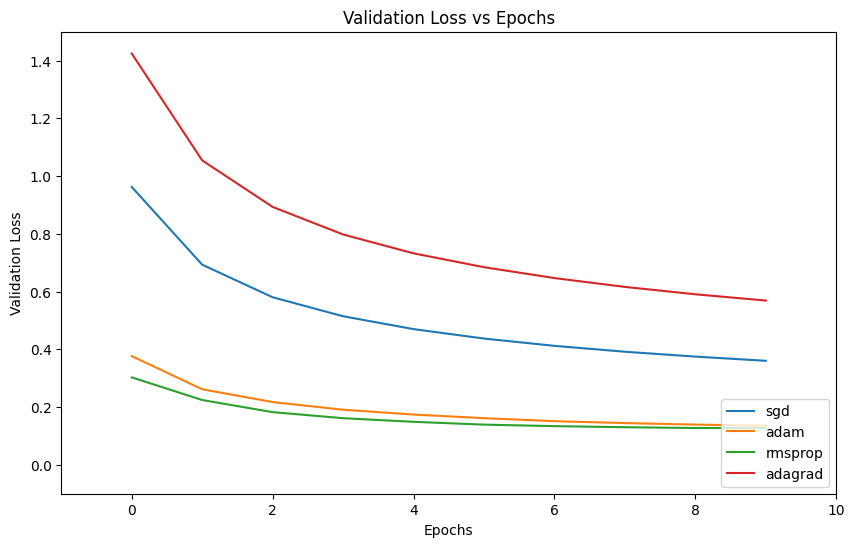

In [57]:
axis = (-1, 10, -0.1, 1.5)
metric = 'val_loss'
title = 'Validation Loss vs Epochs'
y_label = 'Validation Loss'
x_label = 'Epochs'

plot_history_with_optimizers(axis, histories, metric, title, y_label, x_label, optimizers_names)

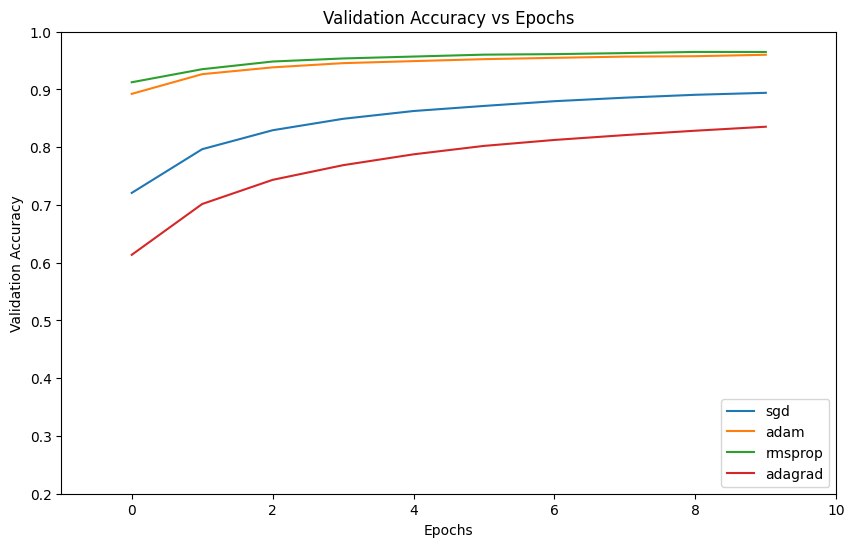

In [58]:
axis = (-1, 10, 0.2, 1)
metric = 'val_accuracy'
title = 'Validation Accuracy vs Epochs'
y_label = 'Validation Accuracy'
x_label = 'Epochs'

plot_history_with_optimizers(axis, histories, metric, title, y_label, x_label, optimizers_names)

# Ejercicio

Variar la arquitectura de la red y experimentar con las técnicas vistas en clase:
* Weight initialization.
* Weight regularization.
* Regularización (Dropout, BatchNormalization).
* Distintos algoritmos de optimización.

In [59]:
import torch
import torch.nn.init as init

class AdvancedNeuralNet(torch.nn.Module):
    def __init__(self):
        super(AdvancedNeuralNet, self).__init__()

        # Capas ocultas con Batch Normalization y Dropout
        self.dense_1 = torch.nn.Linear(784, 256)
        self.bn_1 = torch.nn.BatchNorm1d(256)
        self.relu_1 = torch.nn.ReLU()
        self.dropout_1 = torch.nn.Dropout(p=0.3)

        self.dense_2 = torch.nn.Linear(256, 128)
        self.bn_2 = torch.nn.BatchNorm1d(128)
        self.relu_2 = torch.nn.ReLU()
        self.dropout_2 = torch.nn.Dropout(p=0.3)

        self.output = torch.nn.Linear(128, 10)

        # Inicialización de pesos (Weight Initialization)
        init.kaiming_normal_(self.dense_1.weight, nonlinearity='relu')
        init.kaiming_normal_(self.dense_2.weight, nonlinearity='relu')
        init.xavier_normal_(self.output.weight)

    def forward(self, x):
        x = self.dense_1(x)
        x = self.bn_1(x)
        x = self.relu_1(x)
        x = self.dropout_1(x)

        x = self.dense_2(x)
        x = self.bn_2(x)
        x = self.relu_2(x)
        x = self.dropout_2(x)

        x = self.output(x)
        return x

Iniciando entrenamiento con arquitectura avanzada (MNIST)...


  0%|          | 0/10 [00:00<?, ?it/s]

Epoch 1/10
----> loss: 0.2280 - accuracy: 0.9328 - val_loss: 0.2324 - val_accuracy: 0.9302
Epoch 2/10
----> loss: 0.1592 - accuracy: 0.9536 - val_loss: 0.1768 - val_accuracy: 0.9482
Epoch 3/10
----> loss: 0.1270 - accuracy: 0.9611 - val_loss: 0.1471 - val_accuracy: 0.9568
Epoch 4/10
----> loss: 0.1050 - accuracy: 0.9687 - val_loss: 0.1331 - val_accuracy: 0.9593
Epoch 5/10
----> loss: 0.0894 - accuracy: 0.9725 - val_loss: 0.1220 - val_accuracy: 0.9638
Epoch 6/10
----> loss: 0.0802 - accuracy: 0.9755 - val_loss: 0.1235 - val_accuracy: 0.9656
Epoch 7/10
----> loss: 0.0730 - accuracy: 0.9771 - val_loss: 0.1080 - val_accuracy: 0.9667
Epoch 8/10
----> loss: 0.0652 - accuracy: 0.9795 - val_loss: 0.1078 - val_accuracy: 0.9675
Epoch 9/10
----> loss: 0.0608 - accuracy: 0.9805 - val_loss: 0.1013 - val_accuracy: 0.9693
Epoch 10/10
----> loss: 0.0528 - accuracy: 0.9829 - val_loss: 0.1001 - val_accuracy: 0.9690
Loss     = 0.0628
Accuracy = 0.9820


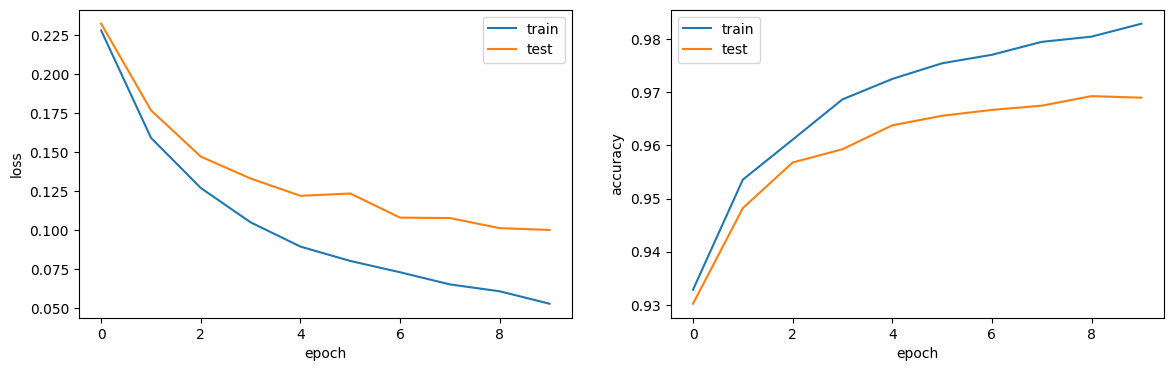

In [60]:
# Instanciar modelo
model_adv = AdvancedNeuralNet()

# Definir Loss y Optimizador (Adam con Weight Decay L2)
loss_function_adv = torch.nn.CrossEntropyLoss()
learning_rate_adv = 0.001
optimizer_adv = torch.optim.Adam(model_adv.parameters(), lr=learning_rate_adv, weight_decay=1e-4)

epochs_adv = 10
print("Iniciando entrenamiento con arquitectura avanzada (MNIST)...")

# Ejecutar entrenamiento
train_losses, test_losses, train_accuracies, test_accuracies = train_model(
    model=model_adv,
    loss_function=loss_function_adv,
    optimizer=optimizer_adv,
    nb=nb,
    bs=bs,
    epochs=epochs_adv,
    x_train=x_train,
    y_train=y_train,
    x_test=x_test,
    y_test=y_test
)

# Mostrar gráficos y resultados finales
model_adv.eval()
show_results(model_adv, train_losses, test_losses, train_accuracies, test_accuracies)

In [61]:
import math
from tensorflow.keras.datasets import fashion_mnist

# Cargar los datos
(x_train_fm, y_train_fm), (x_test_fm, y_test_fm) = fashion_mnist.load_data()

# Ajustar las dimensiones de las imágenes para PyTorch (Flatten a 1D)
x_train_fm = x_train_fm.reshape([-1, 28*28])
x_test_fm = x_test_fm.reshape([-1, 28*28])

print(f'Fashion MNIST Train -> x: {x_train_fm.shape}, y: {y_train_fm.shape}')
print(f'Fashion MNIST Test ->  x: {x_test_fm.shape}, y: {y_test_fm.shape}')

# Recalcular el número de batches
bs_fm = 256
nb_fm = math.ceil(len(x_train_fm) / bs_fm)

29515/29515 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
26421880/26421880 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
5148/5148 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
4422102/4422102 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Fashion MNIST Train -> x: (60000, 784), y: (60000,)
Fashion MNIST Test ->  x: (10000, 784), y: (10000,)


Iniciando entrenamiento con Fashion MNIST...


  0%|          | 0/10 [00:00<?, ?it/s]

Epoch 1/10
----> loss: 0.4341 - accuracy: 0.8463 - val_loss: 0.4739 - val_accuracy: 0.8347
Epoch 2/10
----> loss: 0.4070 - accuracy: 0.8544 - val_loss: 0.4653 - val_accuracy: 0.8357
Epoch 3/10
----> loss: 0.3606 - accuracy: 0.8709 - val_loss: 0.4176 - val_accuracy: 0.8539
Epoch 4/10
----> loss: 0.3291 - accuracy: 0.8798 - val_loss: 0.3959 - val_accuracy: 0.8614
Epoch 5/10
----> loss: 0.3262 - accuracy: 0.8800 - val_loss: 0.4003 - val_accuracy: 0.8589
Epoch 6/10
----> loss: 0.3057 - accuracy: 0.8876 - val_loss: 0.3884 - val_accuracy: 0.8663
Epoch 7/10
----> loss: 0.2848 - accuracy: 0.8945 - val_loss: 0.3792 - val_accuracy: 0.8666
Epoch 8/10
----> loss: 0.2864 - accuracy: 0.8935 - val_loss: 0.3776 - val_accuracy: 0.8661
Epoch 9/10
----> loss: 0.2887 - accuracy: 0.8936 - val_loss: 0.3895 - val_accuracy: 0.8657
Epoch 10/10
----> loss: 0.2662 - accuracy: 0.9022 - val_loss: 0.3642 - val_accuracy: 0.8725

Resultados finales Fashion MNIST:
Loss     = 0.3352
Accuracy = 0.8797


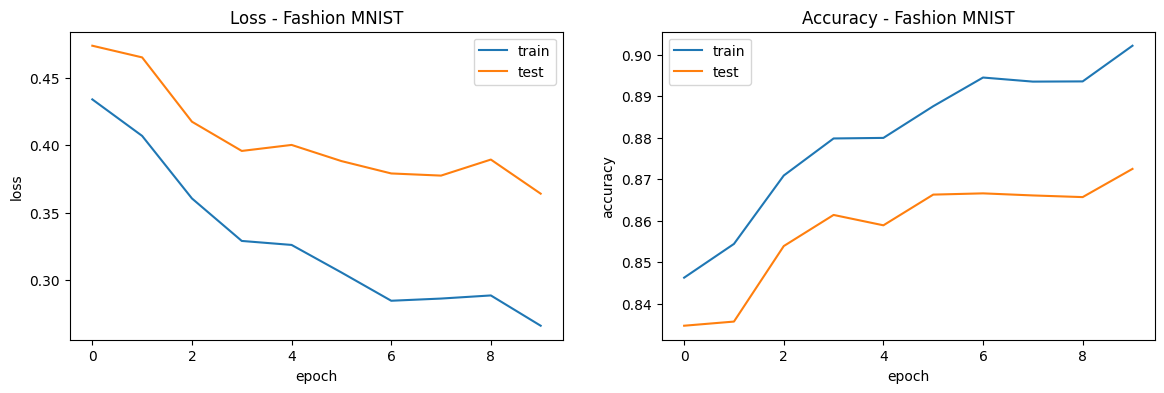

In [62]:
import matplotlib.pyplot as plt

# Reutilizar la arquitectura avanzada
model_fm = AdvancedNeuralNet()

# Definir Loss y Optimizador (RMSprop)
loss_function_fm = torch.nn.CrossEntropyLoss()
optimizer_fm = torch.optim.RMSprop(model_fm.parameters(), lr=0.001, weight_decay=1e-5)

epochs_fm = 10
print("Iniciando entrenamiento con Fashion MNIST...")

train_losses_fm, test_losses_fm, train_accuracies_fm, test_accuracies_fm = train_model(
    model=model_fm,
    loss_function=loss_function_fm,
    optimizer=optimizer_fm,
    nb=nb_fm,
    bs=bs_fm,
    epochs=epochs_fm,
    x_train=x_train_fm,
    y_train=y_train_fm,
    x_test=x_test_fm,
    y_test=y_test_fm
)

# Evaluar de forma independiente para Fashion MNIST
model_fm.eval()
with torch.no_grad():
    x_test_tensor = torch.tensor(x_test_fm, dtype=torch.float32)
    y_test_tensor = torch.tensor(y_test_fm, dtype=torch.int64)
    predictions_fm = model_fm(x_test_tensor)
    loss_fm_val = loss_function_fm(predictions_fm, y_test_tensor).numpy().tolist()
    predictions_softmax = torch.nn.functional.softmax(predictions_fm, dim=-1)
    acc_fm_val = get_accuracy(predictions_softmax, y_test_tensor).numpy().tolist()

print(f'\nResultados finales Fashion MNIST:')
print(f'Loss     = {loss_fm_val:.4f}')
print(f'Accuracy = {acc_fm_val:.4f}')

# Generar gráficos
fig, axes = plt.subplots(1, 2, figsize=(14,4))
ax1, ax2 = axes

ax1.plot(train_losses_fm, label='train')
ax1.plot(test_losses_fm, label='test')
ax1.set_title('Loss - Fashion MNIST')
ax1.set_xlabel('epoch'); ax1.set_ylabel('loss')

ax2.plot(train_accuracies_fm, label='train')
ax2.plot(test_accuracies_fm, label='test')
ax2.set_title('Accuracy - Fashion MNIST')
ax2.set_xlabel('epoch'); ax2.set_ylabel('accuracy')

for ax in axes: ax.legend()
plt.show()

# Otra base de datos para practicar:

``` python
from tensorflow.keras.datasets import fashion_mnist

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout
from tensorflow.keras.initializers import RandomNormal, Zeros
from tensorflow.keras.optimizers import SGD

(x_train, y_train), (x_test, y_test) = fashion_mnist.load_data()

.
.
.
```

In [63]:
import torch
import torch.nn as nn
import torch.optim as optim
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from tensorflow.keras.datasets import fashion_mnist
from tqdm.notebook import tqdm

# Cargar el dataset Fashion MNIST
(x_train_raw, y_train), (x_test_raw, y_test) = fashion_mnist.load_data()

# Etiquetas de las clases en Fashion MNIST
class_names = [
    'T-shirt/top', 'Trouser', 'Pullover', 'Dress', 'Coat',
    'Sandal', 'Shirt', 'Sneaker', 'Bag', 'Ankle boot'
]

print(f"Dimensiones de x_train: {x_train_raw.shape}")
print(f"Dimensiones de y_train: {y_train.shape}")
print(f"Dimensiones de x_test:  {x_test_raw.shape}")
print(f"Dimensiones de y_test:  {y_test.shape}")

Dimensiones de x_train: (60000, 28, 28)
Dimensiones de y_train: (60000,)
Dimensiones de x_test:  (10000, 28, 28)
Dimensiones de y_test:  (10000,)


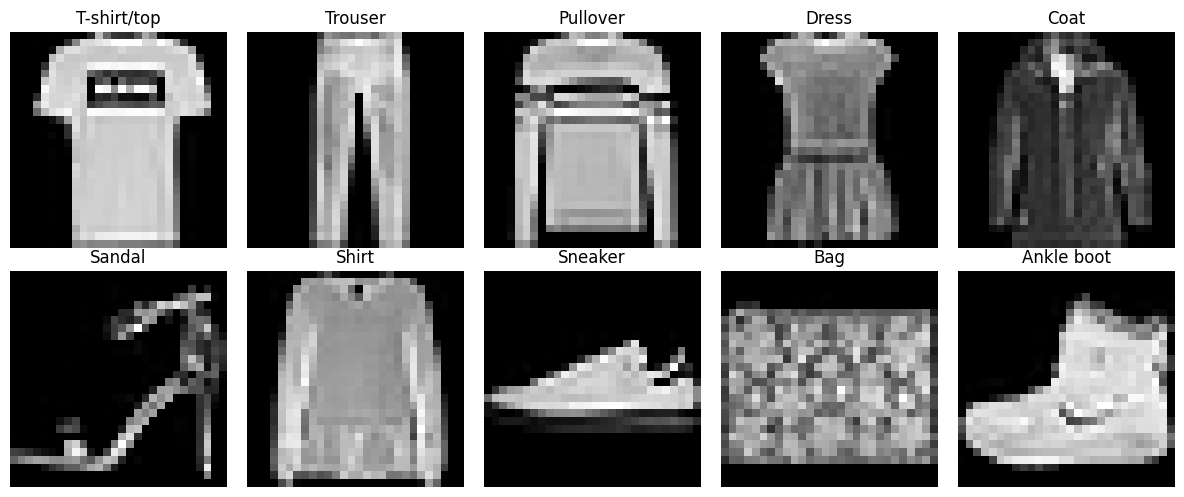

In [64]:
# Mostrar una muestra de imágenes representativas
fig, axes = plt.subplots(2, 5, figsize=(12, 5))
axes = axes.ravel()

for i in range(10):
    idx = np.where(y_train == i)[0][0]
    axes[i].imshow(x_train_raw[idx], cmap='gray')
    axes[i].set_title(class_names[i])
    axes[i].axis('off')

plt.tight_layout()
plt.show()

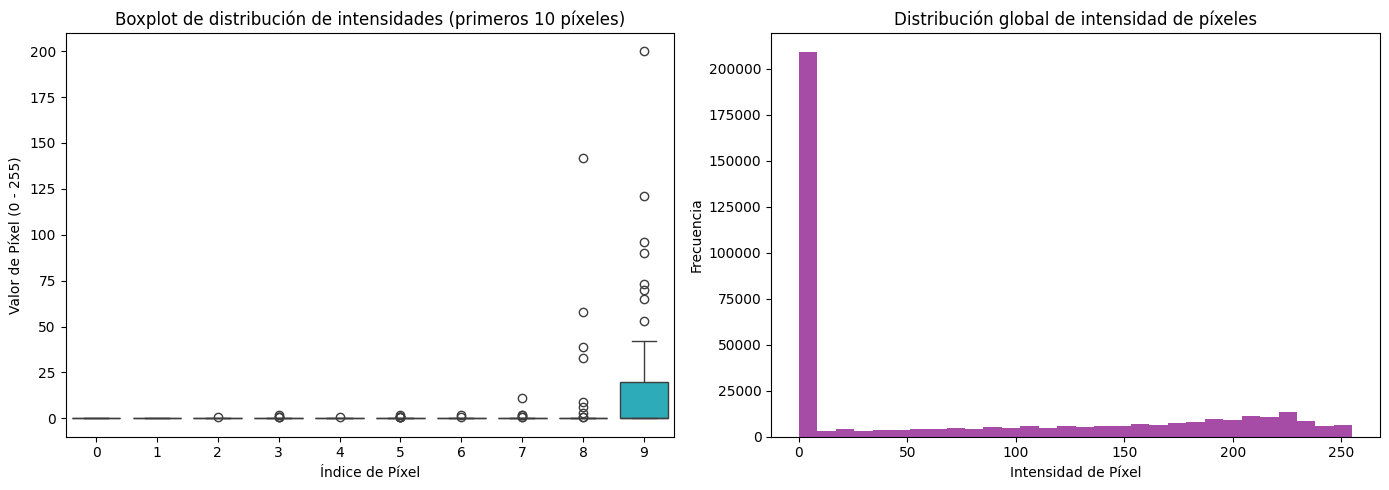

In [65]:
# Boxplot para analizar la distribución de valores de píxeles por muestra
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Tomamos los primeros 1000 píxeles aplanados para visualizar el Boxplot sin saturar la memoria
sample_pixels = x_train_raw[:50].reshape(-1, 28 * 28)

sns.boxplot(data=sample_pixels[:, :10], ax=axes[0])
axes[0].set_title("Boxplot de distribución de intensidades (primeros 10 píxeles)")
axes[0].set_xlabel("Índice de Píxel")
axes[0].set_ylabel("Valor de Píxel (0 - 255)")

# Histograma general de intensidades
axes[1].hist(x_train_raw[:500].ravel(), bins=30, color='purple', alpha=0.7)
axes[1].set_title("Distribución global de intensidad de píxeles")
axes[1].set_xlabel("Intensidad de Píxel")
axes[1].set_ylabel("Frecuencia")

plt.tight_layout()
plt.show()

In [66]:
# Aplanar imágenes de 28x28 a vectores de 784
x_train = x_train_raw.reshape([-1, 28 * 28]).astype(np.float32) / 255.0
x_test = x_test_raw.reshape([-1, 28 * 28]).astype(np.float32) / 255.0

print(f"Forma final de x_train: {x_train.shape}")
print(f"Rango de valores tras normalizar: Min={x_train.min()}, Max={x_train.max()}")

Forma final de x_train: (60000, 784)
Rango de valores tras normalizar: Min=0.0, Max=1.0


In [67]:
class FashionClassifier(nn.Module):
    def __init__(self, use_dropout=True, dropout_rate=0.3):
        super(FashionClassifier, self).__init__()

        self.fc1 = nn.Linear(784, 256)
        self.bn1 = nn.BatchNorm1d(256)
        self.relu1 = nn.ReLU()
        self.dropout1 = nn.Dropout(dropout_rate) if use_dropout else nn.Identity()

        self.fc2 = nn.Linear(256, 128)
        self.bn2 = nn.BatchNorm1d(128)
        self.relu2 = nn.ReLU()
        self.dropout2 = nn.Dropout(dropout_rate) if use_dropout else nn.Identity()

        self.out = nn.Linear(128, 10)

        self._init_weights()

    def _init_weights(self):
        # Inicialización de He (Kaiming) para capas con ReLU
        for m in self.modules():
            if isinstance(m, nn.Linear):
                nn.init.kaiming_normal_(m.weight, nonlinearity='relu')
                if m.bias is not None:
                    nn.init.zeros_(m.bias)

    def forward(self, x):
        x = self.dropout1(self.relu1(self.bn1(self.fc1(x))))
        x = self.dropout2(self.relu2(self.bn2(self.fc2(x))))
        return self.out(x)

model = FashionClassifier(use_dropout=True)
print(model)

FashionClassifier(
  (fc1): Linear(in_features=784, out_features=256, bias=True)
  (bn1): BatchNorm1d(256, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (relu1): ReLU()
  (dropout1): Dropout(p=0.3, inplace=False)
  (fc2): Linear(in_features=256, out_features=128, bias=True)
  (bn2): BatchNorm1d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (relu2): ReLU()
  (dropout2): Dropout(p=0.3, inplace=False)
  (out): Linear(in_features=128, out_features=10, bias=True)
)


In [68]:
def train_and_evaluate(model, optimizer, criterion, epochs=10, batch_size=256):
    nb = int(np.ceil(len(x_train) / batch_size))

    train_losses, test_losses = [], []
    train_accs, test_accs = [], []

    for epoch in range(epochs):
        model.train()
        running_loss = 0.0
        correct_train = 0

        for i in range(nb):
            bx = torch.tensor(x_train[i*batch_size:(i+1)*batch_size])
            by = torch.tensor(y_train[i*batch_size:(i+1)*batch_size], dtype=torch.long)

            optimizer.zero_grad()
            preds = model(bx)
            loss = criterion(preds, by)
            loss.backward()
            optimizer.step()

            running_loss += loss.item() * bx.size(0)
            correct_train += (preds.argmax(dim=1) == by).sum().item()

        epoch_train_loss = running_loss / len(x_train)
        epoch_train_acc = correct_train / len(x_train)

        # Evaluación en test
        model.eval()
        with torch.no_grad():
            tx = torch.tensor(x_test)
            ty = torch.tensor(y_test, dtype=torch.long)

            test_preds = model(tx)
            t_loss = criterion(test_preds, ty).item()
            t_acc = (test_preds.argmax(dim=1) == ty).float().mean().item()

        train_losses.append(epoch_train_loss)
        test_losses.append(t_loss)
        train_accs.append(epoch_train_acc)
        test_accs.append(t_acc)

        print(f"Época {epoch+1:02d}/{epochs:02d} | "
              f"Train Loss: {epoch_train_loss:.4f} - Train Acc: {epoch_train_acc:.4f} | "
              f"Val Loss: {t_loss:.4f} - Val Acc: {t_acc:.4f}")

    return train_losses, test_losses, train_accs, test_accs

In [ ]:
torch.manual_seed(42)

model = FashionClassifier(use_dropout=True, dropout_rate=0.3)
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=0.001, weight_decay=1e-4)

epochs = 15
batch_size = 256

train_losses, test_losses, train_accs, test_accs = train_and_evaluate(
    model, optimizer, criterion, epochs=epochs, batch_size=batch_size
)

Época 01/15 | Train Loss: 0.6064 - Train Acc: 0.7876 | Val Loss: 0.4307 - Val Acc: 0.8442
Época 02/15 | Train Loss: 0.4208 - Train Acc: 0.8493 | Val Loss: 0.3864 - Val Acc: 0.8606
Época 03/15 | Train Loss: 0.3802 - Train Acc: 0.8636 | Val Loss: 0.3660 - Val Acc: 0.8644
Época 04/15 | Train Loss: 0.3527 - Train Acc: 0.8705 | Val Loss: 0.3500 - Val Acc: 0.8730
Época 05/15 | Train Loss: 0.3324 - Train Acc: 0.8792 | Val Loss: 0.3431 - Val Acc: 0.8739
Época 06/15 | Train Loss: 0.3183 - Train Acc: 0.8841 | Val Loss: 0.3425 - Val Acc: 0.8741
Época 07/15 | Train Loss: 0.3060 - Train Acc: 0.8875 | Val Loss: 0.3278 - Val Acc: 0.8790


In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Gráfico de Pérdida
axes[0].plot(train_losses, label='Train Loss', color='blue', linewidth=2)
axes[0].plot(test_losses, label='Validation Loss', color='red', linestyle='--', linewidth=2)
axes[0].set_title("Evolución de la Pérdida (Loss)")
axes[0].set_xlabel("Época")
axes[0].set_ylabel("Pérdida")
axes[0].legend()
axes[0].grid(True, linestyle=':', alpha=0.6)

# Gráfico de Accuracy
axes[1].plot(train_accs, label='Train Accuracy', color='blue', linewidth=2)
axes[1].plot(test_accs, label='Validation Accuracy', color='red', linestyle='--', linewidth=2)
axes[1].set_title("Evolución de la Precisión (Accuracy)")
axes[1].set_xlabel("Época")
axes[1].set_ylabel("Precisión")
axes[1].legend()
axes[1].grid(True, linestyle=':', alpha=0.6)

plt.tight_layout()
plt.show()

In [ ]:
from sklearn.metrics import confusion_matrix, classification_report

model.eval()
with torch.no_grad():
    test_tensor = torch.tensor(x_test)
    raw_preds = model(test_tensor)
    y_pred = raw_preds.argmax(dim=1).numpy()

# Visualización de Matriz de Confusión
cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(10, 8))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=class_names, yticklabels=class_names)
plt.title("Matriz de Confusión en Test")
plt.xlabel("Predicción")
plt.ylabel("Real")
plt.show()

# Impresión de Métricas por Clase
print("\nReporte de Clasificación:")
print(classification_report(y_test, y_pred, target_names=class_names))

In [ ]:
# Mostrar ejemplos de predicciones realizadas por el modelo
fig, axes = plt.subplots(2, 5, figsize=(14, 6))
axes = axes.ravel()

for i in range(10):
    idx = np.random.randint(0, len(x_test))
    img = x_test_raw[idx]
    true_label = class_names[y_test[idx]]
    pred_label = class_names[y_pred[idx]]

    color = 'green' if true_label == pred_label else 'red'

    axes[i].imshow(img, cmap='gray')
    axes[i].set_title(f"Real: {true_label}\nPred: {pred_label}", color=color)
    axes[i].axis('off')

plt.tight_layout()
plt.show()